# QUESTION 5 — LE SPECTATEUR CONSOMMERA-T-IL AU BAR ?

**Objectif :** Prédire si un spectateur consommera au bar à partir des informations disponibles au moment de l'achat de son billet.

**Méthode :** Classification supervisée — K-Nearest Neighbors (KNN)

### 1. Chargement des données

In [94]:
#importation des bibliothèques

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement des données nettoyées

billets = pd.read_csv("../data/processed/billets_clean.csv")
evenements = pd.read_csv("../data/processed/evenements_clean.csv",parse_dates=['date'])

# Vérification des dimensions

print("billets:",billets.shape)
print("evenements:",evenements.shape)

# Aperçu des données

billets.head()



billets: (700, 15)
evenements: (96, 9)


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante,age_inconnu,prix_plancher,invitation
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,False,True,False,False,False
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,False,False,False,False,False
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,False,False,False,False,False
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,False,False,False,False,False
4,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,True,True,False,False,False


### 1.1 Vérification de la structure des données

In [95]:
# Informations générales sur les billets
billets.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   billet_id                700 non-null    str    
 1   evenement_id             700 non-null    str    
 2   zone                     700 non-null    str    
 3   prix_paye_eur            700 non-null    float64
 4   achat_jours_avant        700 non-null    float64
 5   arrivee_min_avant        700 non-null    float64
 6   x_salle_m                700 non-null    float64
 7   y_salle_m                700 non-null    float64
 8   conso_bar_eur            686 non-null    float64
 9   age                      700 non-null    float64
 10  deja_venu                700 non-null    bool   
 11  revient_saison_suivante  700 non-null    bool   
 12  age_inconnu              700 non-null    bool   
 13  prix_plancher            700 non-null    bool   
 14  invitation               700 non-null

### 2. Définition de la variable cible

La question 5 est un problème de classification binaire.
À partir de la variable `conso_bar_eur`, nous définissons
une nouvelle variable cible `conso_bar` :

- 0 : le spectateur ne consomme pas au bar.
- 1 : le spectateur consomme au bar.

Les observations dont la consommation au bar est inconnue
sont exclues de l'apprentissage et de l'évaluation du modèle
afin d'éviter l'attribution artificielle d'une classe.

Cette opération concerne 14 billets sur 700 (2 %).

### 2.1 Traitement des valeurs manquantes de consommation au bar

In [96]:
# Nombre de valeurs manquantes avant

print("Consommations inconnues avant :", billets['conso_bar_eur'].isnull().sum())

# Copie sans les billets dont la consommation est inconnue
# (un NaN n'est pas un 0 : décision de l'audit)

billets_q5 = billets.dropna(subset=['conso_bar_eur']).copy()

# Vérifications après suppression

print("Consommations inconnues après :", billets_q5['conso_bar_eur'].isnull().sum())  
print("Nombre de billets :", len(billets_q5))                                         

Consommations inconnues avant : 14
Consommations inconnues après : 0
Nombre de billets : 686


### 2.2 Création de la variable cible binaire

In [97]:
# Création de la variable cible binaire

billets_q5['conso_bar'] = (billets_q5['conso_bar_eur']>0).astype(int)

# Vérification de la variable cible

billets_q5[['conso_bar_eur','conso_bar']].head(10)

,conso_bar_eur,conso_bar
0,28.63,1
1,10.63,1
2,3.01,1
3,4.71,1
5,12.61,1
6,12.38,1
7,7.47,1
8,0.00,0
9,8.07,1
10,7.01,1


### 2.3 Analyse de la distribution de la variable cible

In [98]:
# Nombre de consommateurs et de non-consommateurs

effectifs = billets_q5['conso_bar'].value_counts().sort_index()

# Pourcentage de chaque classe

Pourcentage = billets_q5['conso_bar'].value_counts(normalize=True).sort_index() *100

# Création d'un tableau récapitulatif

distribution=pd.DataFrame({
    'effectifs':effectifs,
    'Pourcentage (%)':Pourcentage.round(2)
})
display(distribution)



,effectifs,Pourcentage (%)
conso_bar,,
0,72,10.5
1,614,89.5


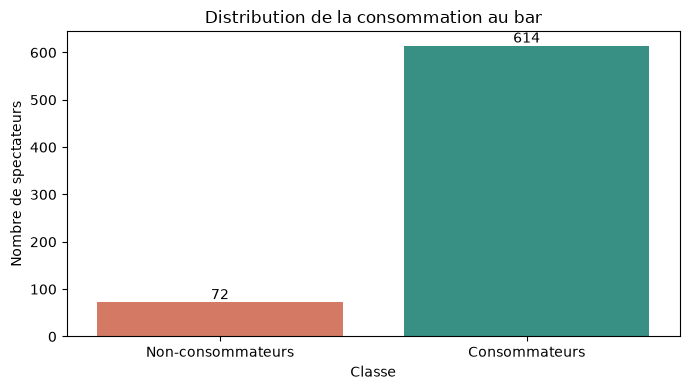

In [99]:
# Visualisation de la distribution des classes
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=billets_q5,
    x='conso_bar',
    hue='conso_bar',
    palette=['#E76F51', '#2A9D8F'],
    legend=False
)

# Affichage des effectifs sur les barres
for container in ax.containers:
    ax.bar_label(container)

plt.title('Distribution de la consommation au bar')
plt.xticks([0, 1], ['Non-consommateurs', 'Consommateurs'])
plt.xlabel('Classe')
plt.ylabel('Nombre de spectateurs')
plt.tight_layout()
plt.show()

**Interprétation :**

La distribution de la variable cible révèle un déséquilibre
important entre les deux classes :

- Classe 0 : 72 non-consommateurs (10,50 %).
- Classe 1 : 614 consommateurs (89,50 %).

Ce déséquilibre peut favoriser la classe majoritaire lors
de l'apprentissage du modèle KNN. L'accuracy seule ne sera
donc pas suffisante pour évaluer ses performances.

Nous utiliserons notamment la précision, le rappel,
le F1-score et la matrice de confusion.